# Clustering & Spatial Domain Identification: Visium HD (Segmented)

## Introduction

In [the previous notebook](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb), we prioritized 1,000 non-mitochondrial Highly Variable Genes (HVGs), benchmarked Spatially Variable Genes (SVGs), and compressed our 33,709 post-QC segmented colorectal adenocarcinoma (CRC) cells into both non-spatial (`PCA`, `UMAP`) and neighborhood-augmented (`PCA_banksy`, `UMAP_banksy`) embeddings. The next analytical step partitions these low-dimensional manifolds into discrete communities that bridge intermediate preprocessing and downstream biological annotation.

As detailed in [the accompanying theoretical note](../assets/notes/07-clustering.md), clustering in spatial transcriptomics serves **two complementary biological goals**:

1. **Non-Spatial Cell-Type Clustering:** Grouping cells strictly by cell-autonomous transcriptomic similarity (`PCA`) to recover _dispersed lineages_ (e.g., plasma cells, fibroblasts, proliferating epithelial cells) regardless of physical location.
2. **Spatially-Aware Domain Identification:** Grouping cells by joint intrinsic expression and local microenvironmental context (`PCA_banksy`, computed with $k_{\text{geom}} = 20$ and $\lambda = 0.8$) to delineate _contiguous anatomical compartments_ (normal colonic mucosa, invasive cribriform adenocarcinoma, and desmoplastic stroma).

> **Note on `BayesSpace`:** Lattice-based Bayesian Potts models such as `BayesSpace` require regular hexagonal or square array coordinates and cannot be applied directly to irregular StarDist-segmented cell polygons. We therefore focus here on graph-based Leiden clustering of standard `PCA` versus `PCA_banksy`, and defer `BayesSpace` to a dedicated 16-µm binned Visium HD notebook.

## Learning objectives

* Construct Shared Nearest Neighbor (SNN) graphs and run Leiden community detection on standard `PCA` embeddings as a non-spatial baseline.
* Perform fast, $O(n)$ spatially-aware domain segmentation by applying SNN + Leiden clustering to the neighborhood-augmented `PCA_banksy` embedding.
* Contrast non-spatial cell clusters against BANKSY spatial domains across both UMAP manifolds and physical tissue coordinates (full ROI and invasive-front zoom).
* Quantify spatial domain compactness using `bluster::neighborPurity()` on physical cell coordinates.
* Preview domain-enriched CRC marker genes via `scrapper::scoreMarkers.se()` and serialize the clustered `SpatialFeatureExperiment` object for downstream annotation.

## Environment setup

### Loading libraries

In [1]:
suppressPackageStartupMessages(suppressWarnings({
  # Core spatial & Bioconductor containers
  library(SpatialFeatureExperiment)
  library(Voyager)
  library(alabaster.sfe)

  # Graph construction, clustering & marker statistics
  library(bluster)
  library(igraph)
  library(scrapper)
  library(scater)

  # Visualization, palettes & layouts
  library(ggplot2)
  library(patchwork)
}))

# Enforce global reproducibility for stochastic graph partitioning
set.seed(42)

### Restoring the reduced-dimension Visium HD dataset

We restore the `SpatialFeatureExperiment` (`sfe`) object exported at the end of [notebook 10](./10-feature_selection_dimensionality_reduction_VisiumHD_segmented.ipynb), which retains 18,049 expressed genes across 33,709 segmented cells along with `PCA`, `PCA_banksy`, `UMAP`, and `UMAP_banksy`.

In [2]:
# Define path to the reduced-dimension Visium HD segmented object
sfe_path <- "output/sfe_visiumhd_segmented_dimred"

# Restore the SFE object using alabaster serialization
sfe <- readObject(sfe_path)

# Verify dimensions, assays, and stored dimensionality reductions
sfe

>>> Reading SpatialExperiment

>>> Reading colgeometries

>>> Reading spatial graphs



class: SpatialFeatureExperiment 
dim: 18049 33709 
metadata(1): Samples
assays(2): counts logcounts
rownames(18049): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(11): ID Symbol ... prop_sv padj
colnames(33709): 80404 80411 ... 189331 189341
colData names(36): Sample Barcode ... sizeFactor_smooth sf_ratio
reducedDimNames(5): PCA_artifacts PCA PCA_banksy UMAP UMAP_banksy
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (POLYGON), nucSeg (POLYGON) 

Graphs:
sample01: col: knn6

## Non-spatial clustering (SNN + Leiden)

As our non-spatial baseline, we adopt the standard scRNA-seq graph-partitioning paradigm: constructing a Jaccard-weighted Shared Nearest Neighbor (SNN) graph in expression-only principal component space (`PCA`) and partitioning it via **Leiden modularity optimization** (`igraph::cluster_leiden()`).

Because `PCA` summarizes the top 1,000 HVGs without physical $(x, y)$ coordinates, every cell is connected solely to its 20 nearest _transcriptomic neighbors_ (`k = 20`). Restricting the graph to the top 10 PCs (`n_dimred = 10`, matching the scree plateau established in the previous notebook) suppresses high-frequency shot noise while retaining the major epithelial, plasma-cell, and stromal axes.

We first build the SNN graph, run Leiden clustering (`resolution` γ = 0.6) to match cell-type granularity, and record the resulting cluster labels in `colData(sfe)[["Leiden"]]`.

In [3]:
# Build Jaccard SNN graph on the top 10 non-spatial PCs
snn_pca <- makeSNNGraph(
  reducedDim(sfe, "PCA")[, 1:10],
  type = "jaccard",
  k = 20
)

In [4]:
# Partition graph using Leiden modularity optimization
set.seed(42)
leiden_pca <- cluster_leiden(
  snn_pca,
  objective_function = "modularity",
  resolution = 0.6
)

In [5]:
# Register cluster labels in colData using exact double-bracket indexing
sfe[["Leiden"]] <- factor(membership(leiden_pca))

In [6]:
table(sfe[["Leiden"]])


   1    2    3    4    5    6    7    8    9   10 
6585 6599 2705 3131 1637 3074  475 4221 4632  650 

To inspect how these expression-only communities map onto both the non-linear manifold and physical CRC histology, we visualize `Leiden` side-by-side in `UMAP` space and across the `cellSeg` polygons, together with our standardized 700 × 700 µm invasive-front viewport (`zoom_xlim = c(13750, 14450)`, `zoom_ylim = c(2400, 3100)`).

In [7]:
# Standardized invasive-front viewport (700 x 700 µm)
zoom_xlim <- c(13750, 14450)
zoom_ylim <- c(2400, 3100)

# Color palette scaled to the number of non-spatial clusters
n_leiden <- nlevels(sfe[["Leiden"]])
pal_leiden <- pals::polychrome(n_leiden)
names(pal_leiden) <- levels(sfe[["Leiden"]])

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


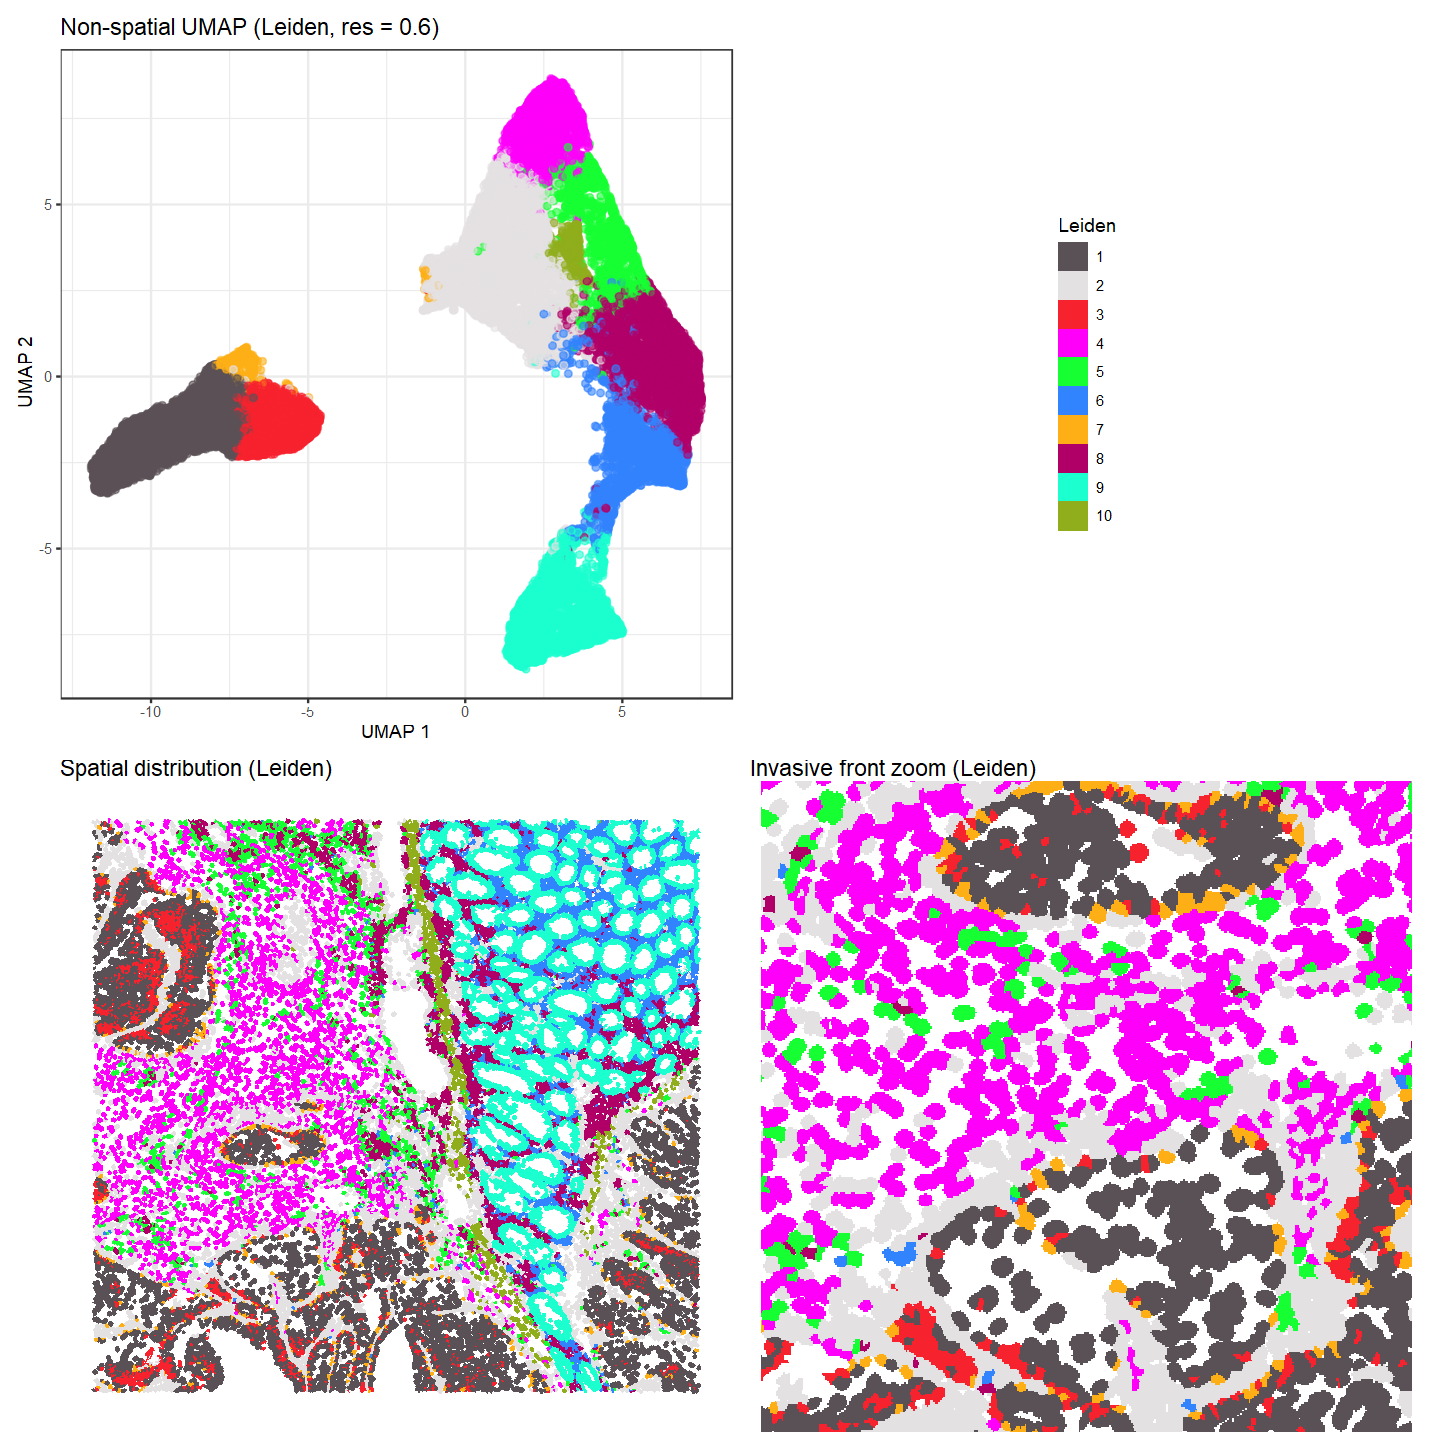

In [8]:
# UMAP projection colored by non-spatial Leiden clusters (suppress duplicate color legend)
p_umap_leiden <- plotReducedDim(sfe, dimred = "UMAP", colour_by = "Leiden") +
  scale_color_manual(values = pal_leiden) +
  guides(color = "none") +
  ggtitle("Non-spatial UMAP (Leiden, res = 0.6)") +
  theme_bw()

# Full ROI spatial map on cellSeg polygons
p_spat_leiden <- plotSpatialFeature(
  sfe,
  features = "Leiden",
  colGeometryName = "cellSeg"
) +
  scale_fill_manual(values = pal_leiden) +
  ggtitle("Spatial distribution (Leiden)")

# Invasive-front zoom (non-destructive coord_sf crop)
p_zoom_leiden <- p_spat_leiden +
  coord_sf(xlim = zoom_xlim, ylim = zoom_ylim) +
  ggtitle("Invasive front zoom (Leiden)")

# 2x2 balanced layout: UMAP (top-left), legend (top-right), spatial maps (bottom)
layout_leiden <- "
AB
CD
"

options(repr.plot.width = 12, repr.plot.height = 12)
(p_umap_leiden + guide_area() + p_spat_leiden + p_zoom_leiden) +
  plot_layout(design = layout_leiden, guides = "collect", heights = c(1, 1))

On the 10-PC SNN graph, modularity optimization at `resolution` γ = 0.6 yields 10 transcriptionally distinct `Leiden` communities (ranging from 475 to 6,599 cells per cluster) that map cleanly onto major colorectal tissue compartments:

* **Normal colonic mucosa & muscularis:** `Cluster 9` (cyan; 4,632 cells, 13.7%) traces the regular epithelial crypts of Lieberkühn in the upper-right ROI, flanked by pericryptal lamina propria and crypt-base populations (`Cluster 8`, 4,221 cells, 12.5%; `Cluster 6`, 3,074 cells, 9.1%), while `Cluster 10` (olive; 650 cells, 1.9%) sharply delineates the diagonal smooth-muscle ribbon of the muscularis mucosae.
* **Invasive colorectal adenocarcinoma:** `Cluster 1` (charcoal; 6,585 cells, 19.5%), `Cluster 3` (red; 2,705 cells, 8.0%), and `Cluster 7` (orange; 475 cells, 1.4%) form the isolated left-hand UMAP island and localize specifically to the crowded cribriform tumor glands, capturing intratumoral epithelial sub-states along glandular rims.
* **Invasive-front immune & stromal infiltration:** In the zoomed invasive-front viewport, `Cluster 4` (magenta; 3,131 cells, 9.3%), `Cluster 5` (green; 1,637 cells, 4.9%), and `Cluster 2` (light grey; 6,599 cells, 19.6%) are densely intermingled between the neoplastic glands. Rather than representing purely technical "salt-and-pepper" noise, this fine-grained spatial mosaic reflects authentic microenvironmental diversity—distinct infiltrating immune populations (such as plasma cells and lymphocytes) interspersed with cancer-associated fibroblasts and extracellular matrix stroma.

Non-spatial `Leiden` excels at preserving these cell-autonomous lineages even when different cell types sit side-by-side. However, when our analytical goal shifts from **cell-type identification** to **macro-scale tissue domain segmentation** (for example, delineating the entire peritumoral immune-stromal bed as a single histological compartment), we require spatially-aware clustering via `Banksy`.

## Spatially-aware clustering (BANKSY + Leiden)

Because **BANKSY** already encodes each cell's microenvironmental context into `PCA_banksy` (computed in the previous notebook at $k_{\text{geom}} = 20$ and $\lambda = 0.8$), no iterative spatial prior is needed during _clustering_. We simply build the same Jaccard SNN graph (`k` = 20) on `PCA_banksy` and run Leiden community detection at a coarser `resolution` γ = 0.2 to segment macro-scale tissue domains.

In [9]:
# Build Jaccard SNN graph on the 10 BANKSY spatio-molecular PCs
snn_banksy <- makeSNNGraph(
  reducedDim(sfe, "PCA_banksy"),
  type = "jaccard",
  k = 20
)

In [10]:
# Partition graph using Leiden modularity optimization at domain resolution
set.seed(42)
leiden_banksy <- cluster_leiden(
  snn_banksy,
  objective_function = "modularity",
  resolution = 0.2
)

# Register BANKSY domain labels in colData
sfe[["Banksy"]] <- factor(membership(leiden_banksy))

In [11]:
table(sfe[["Banksy"]])


   1    2    3    4 
9009 6458 8884 9358 

Although `PCA_banksy` retains 10 spatio-molecular PCs, partitioning its SNN graph at `λ = 0.8` and a coarse `resolution` γ = 0.2 intentionally groups the 33,709 cells into 4 balanced macro-domains (`Domain 1`: 9,009 cells, 26.7%; `Domain 2`: 6,458 cells, 19.2%; `Domain 3`: 8,884 cells, 26.4%; `Domain 4`: 9,358 cells, 27.8%; ≈ 19%–28% each).

Because `PCA_banksy` here was computed in _spatial-domain mode_ (`λ = 0.8`), we do not use `Banksy` in this notebook to resolve dispersed single-cell types—which requires `λ = 0.2`, as explored across the dual-regime Xenium embeddings that we will cluster in detail in a dedicated notebook—and instead rely on `Leiden` for _cell-type granularity_ while using `Banksy` to delineate overarching histological compartments.

To mirror our non-spatial baseline, we project these 4 `Banksy` domains onto the pre-computed `UMAP_banksy` embedding from the previous notebook, the full CRC ROI, and the 700 × 700 µm invasive-front viewport (`zoom_xlim`, `zoom_ylim`).

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


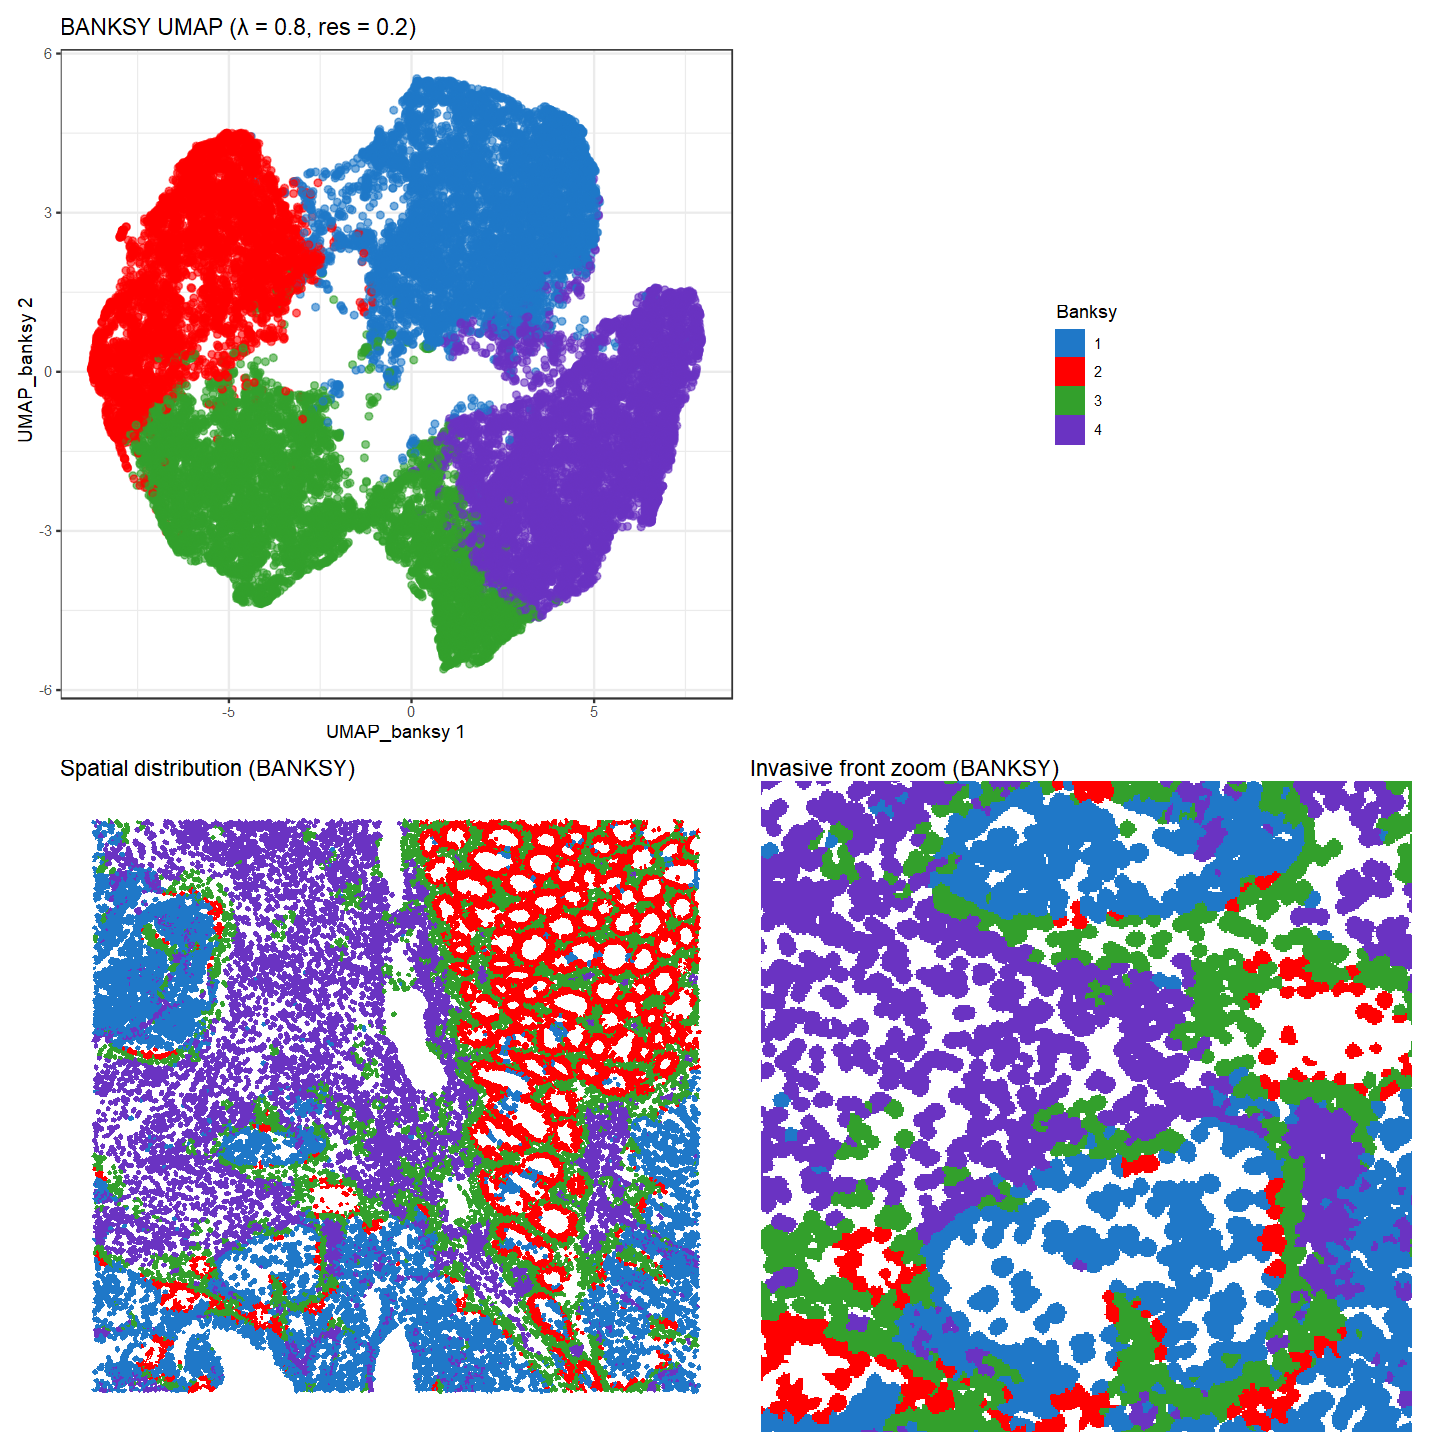

In [12]:
# Color palette for BANKSY spatial domains
n_banksy <- nlevels(sfe[["Banksy"]])
pal_banksy <- pals::cols25(n_banksy)
names(pal_banksy) <- levels(sfe[["Banksy"]])

# BANKSY UMAP projection (suppress duplicate color legend)
p_umap_banksy <- plotReducedDim(sfe, dimred = "UMAP_banksy", colour_by = "Banksy") +
  scale_color_manual(values = pal_banksy) +
  guides(color = "none") +
  ggtitle("BANKSY UMAP (λ = 0.8, res = 0.2)") +
  theme_bw()

# Full ROI spatial map on cellSeg polygons
p_spat_banksy <- plotSpatialFeature(
  sfe,
  features = "Banksy",
  colGeometryName = "cellSeg"
) +
  scale_fill_manual(values = pal_banksy) +
  ggtitle("Spatial distribution (BANKSY)")

# Invasive-front zoom (non-destructive coord_sf crop)
p_zoom_banksy <- p_spat_banksy +
  coord_sf(xlim = zoom_xlim, ylim = zoom_ylim) +
  ggtitle("Invasive front zoom (BANKSY)")

# 2x2 balanced layout matching the non-spatial baseline
layout_banksy <- "
AB
CD
"

options(repr.plot.width = 12, repr.plot.height = 12)
(p_umap_banksy + guide_area() + p_spat_banksy + p_zoom_banksy) +
  plot_layout(design = layout_banksy, guides = "collect", heights = c(1, 1))

In `UMAP_banksy`, the 33,709 cells organize into four contiguous lobes that map onto coherent anatomical compartments across the tissue: `Domain 2` (red) traces the normal epithelial crypts of Lieberkühn, `Domain 1` (blue) delineates the invasive cribriform adenocarcinoma nests, `Domain 3` (green) wraps around the pericryptal lamina propria and the outer rims of tumor glands, and `Domain 4` (purple) unifies the intervening desmoplastic stroma. 

In the invasive-front zoom, `Banksy` eliminates the fine-grained mixing seen in `Leiden` and yields sharp, continuous tumor–stroma boundaries; however, this smoothness comes with an expected loss of immune-infiltration diversity, as distinct infiltrating immune and fibroblast populations resolved by non-spatial `Leiden` (`Clusters 2, 4, 5`) are merged into `Domain 4` and the periglandular cuff (`Domain 3`). 

Retaining both complementary partitions—`Leiden` for cell-type–level states and `Banksy` for the 4 macro-scale tissue domains—provides the ideal foundation for the next module, where fine-grained cell-type annotation can be evaluated directly against both cluster granularity and spatial domain composition.

## Evaluating spatial coherence (Spatial Neighbor Purity)

To quantify spatial continuity objectively without ground-truth pathologist labels, we compute **spatial neighbor purity** via `bluster::neighborPurity()` directly on physical cell coordinates (`spatialCoords(sfe)`). For each cell $i$, neighbor purity measures the fraction of its $k = 20$ nearest physical neighbors sharing the same cluster label: values near `1.0` indicate spatially contiguous domains, whereas lower values reflect fine-grained local mixing—either from intermingled cell lineages or technical fragmentation.

In [13]:
# Compute physical-space neighbor purity (k = 20) for both clusterings
coords <- spatialCoords(sfe)

purity_leiden <- neighborPurity(coords, clusters = sfe[["Leiden"]], k = 20)
purity_banksy <- neighborPurity(coords, clusters = sfe[["Banksy"]], k = 20)

# Compare summary distributions quantitatively
cat("Spatial Neighbor Purity — Non-spatial Leiden:\n")
print(summary(purity_leiden[["purity"]]))

cat("\nSpatial Neighbor Purity — BANKSY Domains:\n")
print(summary(purity_banksy[["purity"]]))

Spatial Neighbor Purity — Non-spatial Leiden:
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
0.006207 0.319029 0.548979 0.549072 0.778234 1.000000 

Spatial Neighbor Purity — BANKSY Domains:
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.01853 0.57967 0.78579 0.74191 0.96429 1.00000 


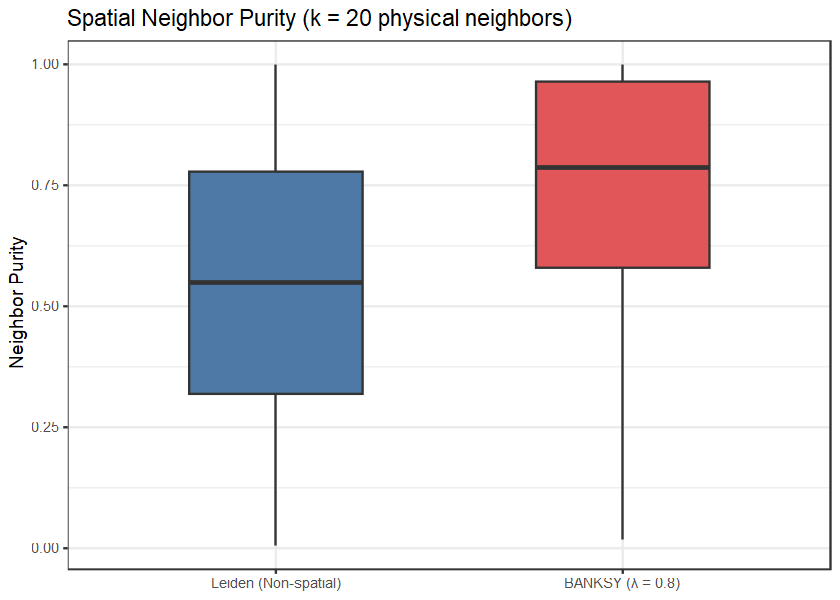

In [14]:
# Combine into a tidy data.frame for visualization
purity_df <- data.frame(
  purity = c(purity_leiden[["purity"]], purity_banksy[["purity"]]),
  method = factor(
    rep(c("Leiden (Non-spatial)", "BANKSY (λ = 0.8)"), each = ncol(sfe)),
    levels = c("Leiden (Non-spatial)", "BANKSY (λ = 0.8)")
  )
)

options(repr.plot.width = 7, repr.plot.height = 5)
ggplot(purity_df, aes(x = method, y = purity, fill = method)) +
  geom_boxplot(width = 0.5, outlier.size = 0.3, outlier.alpha = 0.25) +
  scale_fill_manual(values = c("#4E79A7", "#E15759")) +
  labs(
    title = "Spatial Neighbor Purity (k = 20 physical neighbors)",
    x = NULL,
    y = "Neighbor Purity"
  ) +
  theme_bw() +
  theme(legend.position = "none")

`Banksy` achieves substantially higher median and interquartile spatial neighbor purity than `Leiden`, quantitatively confirming its transition from intermingled cell-type states to contiguous anatomical domains. Lower-purity cells in `Leiden` arise largely within the immune- and fibroblast-rich invasive front where distinct lineages sit side-by-side, whereas residual low-purity cells in `Banksy` localize primarily along thin histological interfaces—such as the periglandular cuffs (`Domain 3`) separating invasive tumor nests from surrounding stroma.

## Biological sanity check: previewing domain markers

Before moving to formal reference-based cell-type annotation in the next notebook, we perform a lightweight sanity check using `scrapper::scoreMarkers.se()` on `logcounts`. Using `scrapper::previewMarkers()`, we inspect the top 3 genes per `Banksy` domain—summarized by their within-domain `mean` log-expression, `detected` cell fraction, and mean log-fold change (`lfc`) relative to the other domains—to assess whether the 4 compartments reflect coherent biological signatures rather than technical artifacts.

In [15]:
# Lightweight sanity check: score markers per BANKSY domain (C++-accelerated via scrapper)
markers_banksy <- scoreMarkers.se(
  sfe,
  groups = sfe[["Banksy"]],
  assay.type = "logcounts"
)

using unknown matrix fallback for 'CSC_H5SparseMatrixSeed'



In [16]:
# Preview top 3 markers per BANKSY domain
lapply(markers_banksy, previewMarkers, rows = 3)

$`1`
DataFrame with 3 rows and 3 columns
             mean  detected       lfc
        <numeric> <numeric> <numeric>
CEACAM6   1.83277  0.881008   1.57880
CEACAM5   2.10711  0.921412   1.49931
PYGB      1.48743  0.849151   1.20822

$`2`
DataFrame with 3 rows and 3 columns
           mean  detected       lfc
      <numeric> <numeric> <numeric>
PIGR    3.03585  0.803500   2.83878
LCN2    1.42387  0.648343   1.30053
FCGBP   1.57580  0.619697   1.47912

$`3`
DataFrame with 3 rows and 3 columns
            mean  detected       lfc
       <numeric> <numeric> <numeric>
IGKC     4.56382  0.778028  2.441176
VIM      1.95915  0.770036  0.906383
JCHAIN   1.87506  0.490882  1.315522

$`4`
DataFrame with 3 rows and 3 columns
            mean  detected       lfc
       <numeric> <numeric> <numeric>
COL3A1   3.04480  0.796965   2.22886
COL1A1   2.60738  0.726437   2.03935
SPARC    1.94305  0.692456   1.48005


The top effect-size markers confirm that our 4 unsupervised `Banksy` domains correspond directly to distinct colorectal tissue compartments rather than technical artifacts: `Domain 1` captures invasive colorectal adenocarcinoma (`CEACAM6` `lfc` = 1.58, `CEACAM5` `lfc` = 1.50, `PYGB` `lfc` = 1.21, detected in 84.9%–92.1% of cells), `Domain 2` isolates normal mucosal crypts and goblet/secretory epithelium (`PIGR` `lfc` = 2.84, `FCGBP` `lfc` = 1.48, `LCN2` `lfc` = 1.30), `Domain 3` delineates plasma-cell–enriched immune and mesenchymal infiltrates (`IGKC` `mean` = 4.56, `lfc` = 2.44; `JCHAIN` `lfc` = 1.32; `VIM` `lfc` = 0.91), and `Domain 4` recovers the collagenous desmoplastic stroma (`COL3A1` `lfc` = 2.23, `COL1A1` `lfc` = 2.04, `SPARC` `lfc` = 1.48). Having verified that these macro-domains are biologically coherent, we next proceed to formal reference-based cell-type annotation in the following module.

## Finalization

We serialize the clustered `SpatialFeatureExperiment` object—now enriched with `colData(sfe)[["Leiden"]]` and `colData(sfe)[["Banksy"]]`—to disk via `alabaster.sfe::saveObject()` for downstream reference-based cell-type annotation.

In [17]:
# Last check of the SFE object
sfe

class: SpatialFeatureExperiment 
dim: 18049 33709 
metadata(1): Samples
assays(2): counts logcounts
rownames(18049): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(11): ID Symbol ... prop_sv padj
colnames(33709): 80404 80411 ... 189331 189341
colData names(38): Sample Barcode ... Leiden Banksy
reducedDimNames(5): PCA_artifacts PCA PCA_banksy UMAP UMAP_banksy
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (POLYGON), nucSeg (POLYGON) 

Graphs:
sample01: col: knn6

In [18]:
# Define standardized output directory
output_dir <- "output/sfe_visiumhd_segmented_clustered"

# Replace existing directory cleanly if present
if (dir.exists(output_dir)) {
  unlink(output_dir, recursive = TRUE)
}

# Serialize clustered SFE object
saveObject(sfe, output_dir)

# Verify directory creation
fs::dir_tree(output_dir)

>>> Saving SpatialExperiment

>>> Saving colgeometries

>>> Saving spatial graphs



output/sfe_visiumhd_segmented_clustered
├── assays
│   ├── 0
│   │   ├── matrix.h5
│   │   └── OBJECT
│   ├── 1
│   │   ├── matrix.h5
│   │   └── OBJECT
│   └── names.json
├── colgeometries
│   ├── 0
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 1
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 2
│   │   ├── map.parquet
│   │   └── OBJECT
│   └── names.json
├── column_data
│   ├── basic_columns.h5
│   ├── OBJECT
│   └── other_columns
│       └── 26
│           ├── array.h5
│           └── OBJECT
├── coordinates
│   ├── array.h5
│   └── OBJECT
├── images
│   ├── 0
│   │   ├── image.tiff
│   │   └── OBJECT
│   ├── 1
│   │   ├── image.tiff
│   │   └── OBJECT
│   └── mapping.h5
├── OBJECT
├── other_data
│   ├── list_contents.json.gz
│   └── OBJECT
├── reduced_dimensions
│   ├── 0
│   │   ├── array.h5
│   │   ├── attrs
│   │   │   ├── list_contents.json.gz
│   │   │   └── OBJECT
│   │   └── OBJECT
│   ├── 1
│   │   ├── array.h5
│   │   ├── attrs
│   │   │   ├── list_contents.json.gz

We clear the workspace and trigger garbage collection to release several gigabytes of spatial polygon geometries and count matrices from memory before opening the next module.

In [19]:
rm(list = ls())
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,12651988,675.7,23764634,1269.2,23764634,1269.2
Vcells,43223810,329.8,149058375,1137.3,138424160,1056.1
